In [7]:
# === Sanity import & device ===
import importlib, sys, torch, numpy as np
import matplotlib.pyplot as plt

import cwt_utils
importlib.reload(cwt_utils)

print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("cwt_utils loaded from:", cwt_utils.__file__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE
if DEVICE: gpu = torch.cuda.get_device_name()
gpu

PyTorch: 2.5.1 | CUDA available: True
cwt_utils loaded from: c:\Deepfake\cwt_utils.py


'NVIDIA GeForce RTX 4090'

In [8]:
# === Test sintético: seno + chirp ===
from cwt_utils import CWT1D

def make_sine_series(T=64, fs=30.0, f0=1.2, amp=1.0):
    t = np.arange(T)/fs
    s = amp*np.sin(2*np.pi*f0*t).astype(np.float32)
    return s

def make_chirp_series(T=64, fs=30.0, f0=0.6, f1=2.0, amp=1.0):
    t = np.arange(T)/fs
    k = (f1 - f0) / (T/fs)   # sweep rate (Hz/s)
    phase = 2*np.pi*(f0*t + 0.5*k*t**2)
    s = amp*np.sin(phase).astype(np.float32)
    return s

# Construimos stack [T,1,H,W] con un único "píxel" (H=W=1)
fs = 30.0
T  = 64
sine = make_sine_series(T=T, fs=fs, f0=1.2)
chirp = make_chirp_series(T=T, fs=fs, f0=0.6, f1=2.0)

def to_tchw(x1d):
    x = x1d[:, None, None]           # [T,1,1]
    x = x.astype(np.float32)
    x = x[:, None, :, :]             # [T,1,1,1]
    return x

x_sine  = to_tchw(sine)
x_chirp = to_tchw(chirp)

# CWT (ROI) directo sobre cada señal
from cwt_utils import cwt_over_roi

cwt_cfg = dict(kernel_size=129, w0=6.5, n_bands=24, fmin=0.4, fmax=12.0)
W_sine,  freqs = cwt_over_roi(x_sine,  fps=fs, cwt_cfg=cwt_cfg)
W_chirp, _     = cwt_over_roi(x_chirp, fps=fs, cwt_cfg=cwt_cfg)

print("W_sine:",  W_sine.shape, "freqs:", freqs.shape)
print("W_chirp:", W_chirp.shape)

# Verificación 1: la banda de mayor energía en el seno cae cerca de f0
k_peak = np.argmax(W_sine.mean(axis=1))
f_hat  = float(freqs[k_peak])
print(f"[SINE] f0=1.2 Hz  | f_hat≈{f_hat:.3f} Hz  | Δf={abs(f_hat-1.2):.3f} Hz")
assert abs(f_hat-1.2) < 0.4, "El pico de frecuencia estimado está demasiado lejos (tolerancia 0.4 Hz)."

# Verificación 2: el chirp debe mostrar cresta creciente
ridge_idx = np.argmax(W_chirp, axis=0)   # [T]
is_increasing = ridge_idx[-1] > ridge_idx[0]
print(f"[CHIRP] cresta creciente: {is_increasing} (idx0={ridge_idx[0]}, idxT={ridge_idx[-1]})")
assert is_increasing, "La cresta del chirp no parece aumentar."


W_sine: (24, 64) freqs: (24,)
W_chirp: (24, 64)
[SINE] f0=1.2 Hz  | f_hat≈1.126 Hz  | Δf=0.074 Hz
[CHIRP] cresta creciente: True (idx0=7, idxT=9)


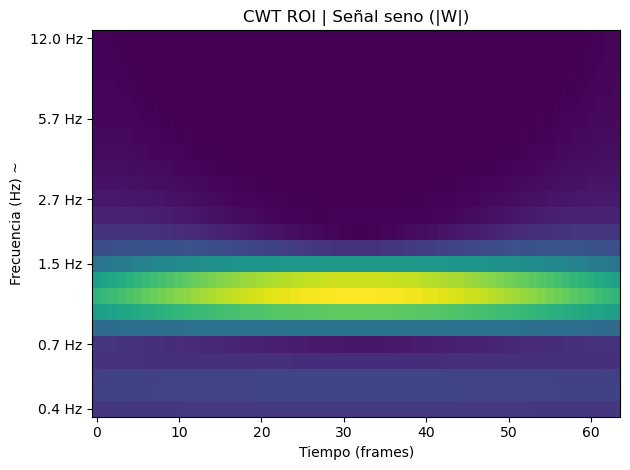

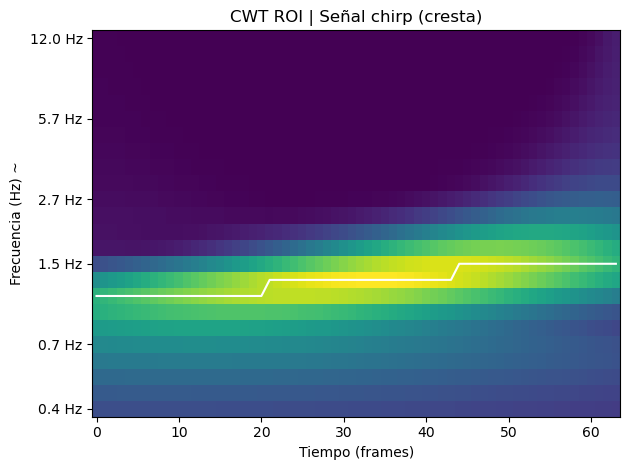

In [9]:
from cwt_utils import plot_roi_spectrogram, plot_chirp_ridge

plot_roi_spectrogram(W_sine,  freqs, title="CWT ROI | Señal seno (|W|)")
plot_chirp_ridge(W_chirp, freqs, title="CWT ROI | Señal chirp (cresta)")


In [10]:
# === Video quick smoke test (ROI + GRID) ===
from cwt_utils import load_video_frames, to_grayscale, detrend_per_pixel, \
                       cwt_over_roi, cwt_per_pixel_downsample, plot_band_maps

VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\real\01__exit_phone_room.mp4"  # cambia si quieres

frames_rgb, fps_eff = load_video_frames(
    VIDEO_PATH, target_fps=30.0, max_frames=48, resize=(192,192)
)
x = to_grayscale(frames_rgb)
x = detrend_per_pixel(x)

# ROI
W_roi, freqs = cwt_over_roi(x, fps=fps_eff, cwt_cfg=dict(kernel_size=95, w0=6.5, n_bands=16, fmin=0.5, fmax=12.0))
print("ROI:", W_roi.shape, "| freqs[0:5]=", np.round(freqs[:5], 2))

# GRID (rápido)
W_maps, _ = cwt_per_pixel_downsample(x, fps=fps_eff, grid=(12,12), cwt_cfg=dict(kernel_size=95, w0=6.5, n_bands=16, fmin=0.5, fmax=12.0))
print("GRID maps:", W_maps.shape, "(S,T,Gh,Gw)")

# Plots
plot_roi_spectrogram(W_roi, freqs, title="Video ROI (|W|)")
plot_chirp_ridge(W_roi, freqs, title="Video ROI (cresta)")
sel = np.linspace(1, len(freqs)-2, num=min(3, len(freqs)-2), dtype=int).tolist()
plot_band_maps(W_maps, freqs, band_indices=sel)


RuntimeError: No pude abrir el video: C:\Deepfake\Datasets\FF++\real\01__exit_phone_room.mp4

DENSE maps: (12, 32, 96, 96) (S,T,H,W)


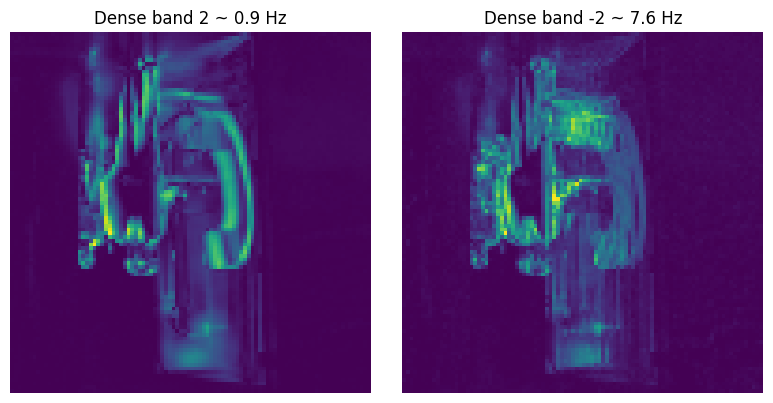

In [ ]:
# === Pixelwise denso (cada píxel) con seguridad de VRAM ===
from cwt_utils import cwt_per_pixel_dense

# para evitar explotar memoria, usamos un clip pequeño
frames_rgb_small, fps_small = load_video_frames(
    VIDEO_PATH, target_fps=30.0, max_frames=32, resize=(96,96)
)
x_small = detrend_per_pixel(to_grayscale(frames_rgb_small))

W_full, freqs_d = cwt_per_pixel_dense(
    x_small, fps=fps_small, batch_size=1024,
    cwt_cfg=dict(kernel_size=95, w0=6.5, n_bands=12, fmin=0.5, fmax=10.0)
)
print("DENSE maps:", W_full.shape, "(S,T,H,W)")

# Visual: energía por banda promedio temporal para 2 bandas
E = W_full.mean(axis=1)  # [S,H,W]
plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(E[2], origin='lower'); plt.title(f"Dense band 2 ~ {freqs_d[2]:.1f} Hz"); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(E[-2], origin='lower'); plt.title(f"Dense band -2 ~ {freqs_d[-2]:.1f} Hz"); plt.axis('off')
plt.tight_layout(); plt.show()


In [ ]:
# === Convertir CWT GRID a tokens de entrada (ej. TimeSformer) ===
import torch
from cwt_utils import CWTtoTokens

# tomamos el W_maps de la Celda 4 (GRID): [S,T,Gh,Gw]
W_maps_t = torch.from_numpy(W_maps).unsqueeze(0).to(torch.float32)  # [1,S,T,Gh,Gw]

tok = CWTtoTokens(S=W_maps_t.shape[1], patch=1, reduce_channels=64, embed_dim=256)
tokens = tok(W_maps_t)  # [1,T,Np,256]
print("Tokens shape:", tokens.shape)  # esperado: [1, T, Gh*Gw, 256]


Tokens shape: torch.Size([1, 48, 144, 256])


In [ ]:
# === Import / reload / device ===
import importlib, torch, numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn

import diff_utils as DU
importlib.reload(DU)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())


PyTorch: 2.7.0+cu126 | CUDA: True


In [ ]:
# === Schedule (cosine) ===
T = 300
sched = DU.build_schedule(T, device=DEVICE)  # cosine (Nichol&Dhariwal)

for k in ("betas","alphas","abar"):
    ten = sched[k]
    print(k, ten.shape, "min=%.3e max=%.3e" % (ten.min().item(), ten.max().item()))

# Verifica monotonicidad esperada
assert torch.all(sched["alphas"] > 0)
assert torch.all(sched["abar"][1:] <= sched["abar"][:-1] + 1e-7)  # abar debe decrecer o mantenerse
print("Schedule OK.")


betas torch.Size([300]) min=1.565e-04 max=9.990e-01
alphas torch.Size([300]) min=1.000e-03 max=9.998e-01
abar torch.Size([300]) min=2.699e-08 max=9.998e-01
Schedule OK.


In [ ]:
# === Forward diffusion y reconstrucción x0 ===
B, C, H, W = 4, 1, 64, 64
x0 = torch.randn(B, C, H, W, device=DEVICE)

# Toma t aleatorio y muestrea x_t
t = torch.randint(1, T+1, (B,), device=DEVICE)
xt, eps_true = DU.sample_xt(x0, t, sched)

# Reconstrucción teórica de x0 (DDPM)
abar_t = sched["abar"][t-1].view(B,1,1,1)
x0_hat = (xt - torch.sqrt(1.0 - abar_t) * eps_true) / torch.sqrt(abar_t)

mse = (x0_hat - x0).pow(2).mean().item()
print(f"Recon x0 MSE ~ {mse:.3e} (debería ser ~0 dentro de precisión numérica)")
assert mse < 1e-6, "Reconstrucción de x0 inesperadamente alta."


Recon x0 MSE ~ 3.963e-15 (debería ser ~0 dentro de precisión numérica)


In [ ]:
# === Un paso de entrenamiento (ε-MSE) + ELBO_est ===
model = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=2e-4)

ds = DU.ToyDataset(n=512, size=64)  # pequeño para smoke
dl = torch.utils.data.DataLoader(ds, batch_size=32, shuffle=True, drop_last=True)

x0_batch = next(iter(dl)).to(DEVICE)
loss_simple, elbo_est = DU.train_step(model, x0_batch, sched, opt)

print("loss_simple:", float(loss_simple), "| ELBO_est (↓ mejor):", float(elbo_est))


loss_simple: 1.012335181236267 | ELBO_est (↓ mejor): 0.02782835066318512


== ELBO (batch) ==
ELBO_sum (↓ mejor): {'mean': 460.73858642578125, 'std': 11.640951156616211, 'min': 427.2315979003906, 'max': 480.67694091796875}
LT_sum: {'mean': 4.398457349452656e-07, 'std': 7.44775476846371e-08, 'min': 2.925580702139996e-07, 'max': 6.17706689354236e-07}
KL_sum: {'mean': 464.605224609375, 'std': 11.64000415802002, 'min': 431.0972595214844, 'max': 484.5237731933594}
L0_sum: {'mean': -3.8666303157806396, 'std': 0.013859603554010391, 'min': -3.8934731483459473, 'max': -3.8350322246551514}


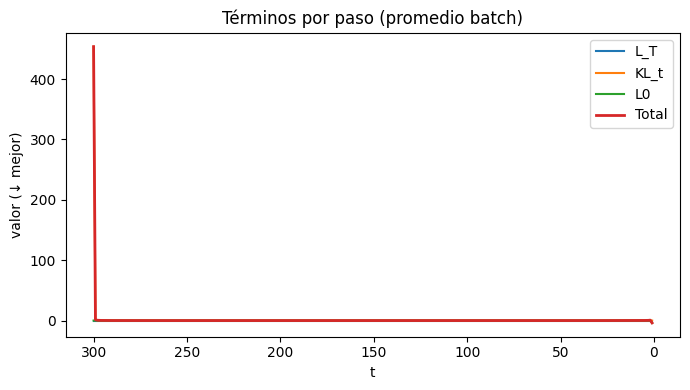

In [ ]:
# === ELBO por paso (curvas) y acumulado ===
with torch.no_grad():
    steps = DU.elbo_per_timestep(model, x0_batch, T=T, sched=sched, t_order="desc")
    acc = DU.accumulate_per_timestep(steps)
    DU.print_summary(acc, "ELBO (batch)")

# Plot rápido per-step (promedio batch)
ts = [s.t for s in steps]
LT = torch.stack([s.LT.mean()   for s in steps]).cpu().numpy()
KL = torch.stack([s.KL_t.mean() for s in steps]).cpu().numpy()
L0 = torch.stack([s.L0.mean()   for s in steps]).cpu().numpy()
TOT= torch.stack([s.total.mean() for s in steps]).cpu().numpy()

plt.figure(figsize=(7,4))
plt.plot(ts, LT, label="L_T")
plt.plot(ts, KL, label="KL_t")
plt.plot(ts, L0, label="L0")
plt.plot(ts, TOT, label="Total", linewidth=2)
plt.gca().invert_xaxis()
plt.xlabel("t"); plt.ylabel("valor (↓ mejor)"); plt.title("Términos por paso (promedio batch)")
plt.legend(); plt.tight_layout(); plt.show()


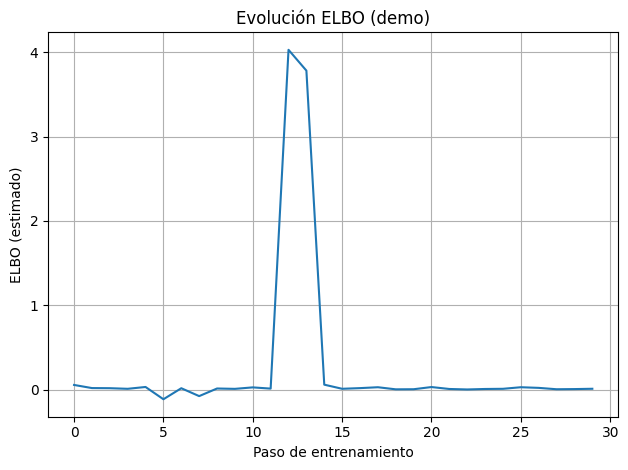

Último step — loss_simple=0.1865 | ELBO_est=0.0128


In [ ]:
# === Mini loop de entrenamiento y curva ELBO ===
elbo_curve = []
epochs, steps_per_epoch = 1, 30
dl_iter = iter(dl)

model.train()
for _ in range(epochs * steps_per_epoch):
    try:
        x0_batch = next(dl_iter).to(DEVICE)
    except StopIteration:
        dl_iter = iter(dl)
        x0_batch = next(dl_iter).to(DEVICE)
    loss_simple, elbo_est = DU.train_step(model, x0_batch, sched, opt)
    elbo_curve.append(float(elbo_est))

DU.plot_elbo_curve(elbo_curve, title="Evolución ELBO (demo)")
print("Último step — loss_simple=%.4f | ELBO_est=%.4f" % (float(loss_simple), float(elbo_est)))


In [ ]:
# === Comparación A (sin entrenar) vs B (afinando 20 pasos) ===
# Clona modelo "A" sin entrenar
model_A = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(DEVICE)
model_B = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(DEVICE)
model_B.load_state_dict(model_A.state_dict())  # mismo inicio

optB = torch.optim.AdamW(model_B.parameters(), lr=2e-4)

# Afinamos B unos pasos
for _ in range(20):
    try:
        x0_batch = next(dl_iter).to(DEVICE)
    except StopIteration:
        dl_iter = iter(dl)
        x0_batch = next(dl_iter).to(DEVICE)
    DU.train_step(model_B, x0_batch, sched, optB)

# Evaluamos ELBO acumulado por paso en el MISMO batch
x_eval = next(iter(dl)).to(DEVICE)
with torch.no_grad():
    steps_A = DU.elbo_per_timestep(model_A, x_eval, T=T, sched=sched, t_order="desc")
    acc_A = DU.accumulate_per_timestep(steps_A)

    steps_B = DU.elbo_per_timestep(model_B, x_eval, T=T, sched=sched, t_order="desc")
    acc_B = DU.accumulate_per_timestep(steps_B)

print("ELBO_sum mean — A: %.4f | B: %.4f (↓ mejor)" % (acc_A.elbo_sum.mean().item(), acc_B.elbo_sum.mean().item()))
gain = (acc_A.elbo_sum - acc_B.elbo_sum).mean().item()
print("Mejora promedio (A - B) =", gain)


ELBO_sum mean — A: 539.3672 | B: 79.3606 (↓ mejor)
Mejora promedio (A - B) = 460.006591796875


In [ ]:
# === Consistencia ddpm_mean_theta vs posterior ===
with torch.no_grad():
    x0 = next(iter(dl)).to(DEVICE)
    B = x0.size(0)
    t = torch.randint(2, T+1, (B,), device=DEVICE)  # t>1 para evaluar KL_t

    xt, eps_true = DU.sample_xt(x0, t, sched)
    # Modelo dummy: predice el epsilon verdadero (caso ideal)
    class Oracle(nn.Module):
        def forward(self, x, t_idx): return eps_true
    oracle = Oracle().to(DEVICE)

    eps_hat = oracle(xt, t)
    # Posterior y modelo
    LT, KL_t, L0 = DU.compute_vlb_terms(x0, eps_hat, xt, t, sched)

print("Con eps_hat = eps_true (oráculo) — KL_t mean: %.3e (≈0)" % KL_t.mean().item())


Con eps_hat = eps_true (oráculo) — KL_t mean: 1.427e-09 (≈0)


In [ ]:
from train_utils import train_eps_unet_on_dfdc

ROOT = r"E:\ERIS\Ernesto\dfdc_train_all"  # carpeta que contiene dfdc_train_part_0..49

res = train_eps_unet_on_dfdc(
    root=ROOT,
    outdir="./checkpoints_dfdc_eps",
    parts=tuple(range(0, 4)),     # empieza con pocas partes para probar
    image_size=64,
    channels=1,                   # UNET 1 canal (rápido y suficiente para prior)
    T=300,
    batch_size=64,
    steps_per_epoch=500,
    epochs=2,
    lr=2e-4,
    weight_decay=1e-2,
    samples_per_video=2,          # cuántas muestras por video en dataset
    max_videos=200,               # limita para pruebas
)
print(res)


In [ ]:
from train_utils import elbo_probe_on_dfdc
probes = elbo_probe_on_dfdc(
    ckpt_path="./checkpoints_dfdc_eps/eps_unet_final.pt",
    root=ROOT,
    parts=(0,),
    n_videos=8,
    frames_per_video=8,
    image_size=64,
    channels=1,
    T=300,
)
for p, e in probes:
    print(f"{p} -> ELBO_est mean: {e:.4f}")
